# 04 PROPAGAÇÃO FORMAL DE INCERTEZA, CALIBRAÇÃO DE APONTAMENTO, CORRELAÇÃO RESIDUAL ($L$), FIRN, GIA E BALANÇO DE MASSA

Este caderno documenta a física e a geoestatística da conversão da grade de mudança de elevação ($\text{dh/dt}$) em perda de massa continental ($\text{dM/dt}$ em $\text{Gt/ano}$) e equivalente eustático de nível do mar ($\text{SLE}$ em $\text{mm/ano}$):

$$\frac{dV}{dt} = \sum_{i=1}^{N_{\text{cél}}} \left(\frac{dh_i}{dt} - \frac{d\text{FAC}_i}{dt} - \frac{dB_i}{dt}\right) A_{\text{cél}}, \qquad \frac{dM}{dt} = \rho_{\text{gelo}} \frac{dV}{dt}, \qquad \text{SLE} = -\frac{dM/dt}{361{,}8\text{ Gt/mm}}$$

onde $\rho_{\text{gelo}} = 917\text{ kg m}^{-3}$ (densidade do gelo glacial para perda dinâmica), $\text{FAC}$ é o conteúdo de ar na coluna de firn e $dB/dt$ é a taxa de movimento vertical do embasamento rochoso por Ajuste Isostático Glacial (GIA).


### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 1 | Erro de geolocalização projetado na declividade | curva calibrada $\sigma_{\text{geo}}(s)$ e sensibilidade do alcance $L$ | `thwaites.uncertainty.geolocation`, `error_correlation` |
| 2 | Orçamento de erro de um nó: apontamento vs. variabilidade interanual | `overpass_leverage` + `sigma_dhdt_from_geolocation` numa amostragem orbital sintética | `thwaites.uncertainty.geolocation` |
| 3 | Do dh/dt à massa com erro espacialmente correlacionado | reprodução do balanço DJF e incerteza em função de $L$ | `thwaites.uncertainty.mass_balance` |
| 4 | Correções de firn e GIA; validação contra ATL15 | sensibilidade ao firn, GIA (Caron × GPS) e comparação nó a nó com ATL15 | `thwaites.corrections.firn`, `gia` |
| 5 | Séries temporais sem interpolação | célula do núcleo da Thwaites e massa por temporada | `pipelines/figures/run_grounded_*` |
| 6 | Síntese: orçamento final de massa | — | — |

---

## 1. Calibração Empírica do Erro de Geolocalização Horizontal Projetado na Declividade (`thwaites.uncertainty.geolocation`)

O ATBD do produto oficial ATL14/ATL15 r005 (§3.4.4, Smith et al., 2024) aponta o erro de apontamento/geolocalização horizontal $\sigma_{\text{horiz}}$ projetado sobre a declividade superficial $s = |\nabla h|$ como a fonte dominante de erro vertical correlacionado em escalas de dezenas de quilômetros:

$$\sigma_{\text{geo}}^2(s) = \sigma_{v0}^2 + (\sigma_{\text{horiz}}\,s)^2$$

Em vez de assumir valores tabulados, calibramos essa relação diretamente contra $4.347.847$ segmentos ($40$ grânulos representativos) usando as variáveis `sigma_geo_h` e `dh_fit_dx` do próprio ATL06 r007 na nossa área de estudo, por regressão sobre medianas em $24$ quantis de declividade (evitando a cauda de outliers de `sigma_geo_h` que distorce a regressão OLS global):
- **Piso vertical puro calibrado:** $\sigma_{v0} = 0{,}1326\text{ m}$ ($4\times$ maior que o ruído de fóton `h_li_sigma` mediano de $0{,}034\text{ m}$);
- **Incerteza horizontal calibrada:** $\sigma_{\text{horiz}} = 6{,}19\text{ m}$ ($R^2 = 0{,}9978$), em concordância notável com o requisito de projeto da missão ICESat-2 de $6{,}5\text{ m}$ (Luthcke et al., 2021);
- **Propagação por alavancagem orbital (`overpass_leverage`):** Como o erro de apontamento é constante ao longo dos poucos segundos em que uma passagem $k$ cruza o nó, mas independente entre passagens distintas, sua contribuição para a incerteza da tendência é:
  $$\sigma_{\text{dh/dt, geo}} = \frac{\sigma_{\text{geo}}(s)}{\sqrt{\sum_{k=1}^{K_{\text{pass}}} (t_k - \bar{t})^2}}$$
  Com uma mediana de $93{,}5$ passagens por tile e alavancagem temporal $\sum(t_k - \bar{t})^2 = 355{,}1\text{ ano}^2$, obtém-se $\sigma_{\text{dh/dt, geo}} = 0{,}0075\text{ m/ano}$ contra $\sigma_{\text{dh/dt, jackknife}} = 0{,}0572\text{ m/ano}$ (**razão $= 13{,}5\%$**).
- **Conclusão científica:** Na nossa geometria nodal de $15\text{ km}$, o erro de apontamento é fortemente promediado pelas $\sim 94$ passagens. Portanto, a correlação espacial residual de $20\text{--}154\text{ km}$ **não é instrumental**, mas sim **geofísica** (variabilidade interanual espacialmente coerente de precipitação/firn e dinâmica).

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


block_km,25.0,50.0,75.0,100.0,150.0
method,,,,,
idw,25.6,34.8,70.0,94.6,128.6
oi_markov,34.7,20.5,35.0,103.1,137.0
ordinary_kriging,71.9,21.8,41.0,105.5,154.4


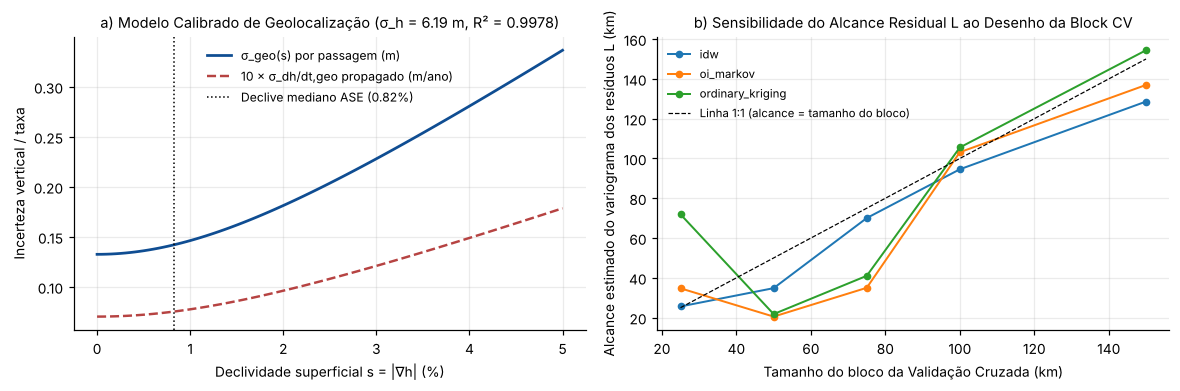

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sig_rep = json.loads((DATA_DIR / "jja_sigma_corr_report.json").read_text(encoding="utf-8"))
err_sens = json.loads((DATA_DIR / "jja_error_correlation_sensitivity.json").read_text(encoding="utf-8"))
firn_sens = pd.read_csv(DATA_DIR / "jja_firn_sensitivity.csv")

# Curva teórica calibrada sigma_geo(s) vs declividade s
s_vals = np.linspace(0, 0.05, 100)
s_v0 = sig_rep["modelo_de_erro"]["sigma_v0_m"]
s_h = sig_rep["modelo_de_erro"]["sigma_horiz_m"]
lev = sig_rep["passagens"]["alavancagem_mediana_ano2"]
sig_geo_curve = np.sqrt(s_v0**2 + (s_h * s_vals)**2)
sig_dhdt_curve = sig_geo_curve / np.sqrt(lev)

df_err_L = pd.DataFrame(err_sens)
df_err_L["range_km"] = df_err_L["range_m"] / 1e3

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
ax[0].plot(s_vals * 100, sig_geo_curve, "-", color="#0F4D92", lw=1.8, label="σ_geo(s) por passagem (m)")
ax[0].plot(s_vals * 100, sig_dhdt_curve * 10, "--", color="#B64342", lw=1.6, label="10 × σ_dh/dt,geo propagado (m/ano)")
ax[0].axvline(sig_rep["nos"]["slope_mediana"] * 100, color="k", ls=":", lw=1.0, label=f"Declive mediano ASE ({100*sig_rep['nos']['slope_mediana']:.2f}%)")
ax[0].set_xlabel("Declividade superficial s = |∇h| (%)")
ax[0].set_ylabel("Incerteza vertical / taxa")
ax[0].set_title(f"a) Modelo Calibrado de Geolocalização (σ_h = {s_h:.2f} m, R² = {sig_rep['modelo_de_erro']['r2']:.4f})")
ax[0].legend(frameon=False, fontsize=8)

for meth, grp in df_err_L.groupby("method"):
    ax[1].plot(grp["block_km"], grp["range_km"], "o-", lw=1.3, ms=4, label=meth)
ax[1].plot([25, 150], [25, 150], "k--", lw=0.8, label="Linha 1:1 (alcance = tamanho do bloco)")
ax[1].set_xlabel("Tamanho do bloco da Validação Cruzada (km)")
ax[1].set_ylabel("Alcance estimado do variograma dos resíduos L (km)")
ax[1].set_title("b) Sensibilidade do Alcance Residual L ao Desenho da Block CV")
ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

df_err_L.pivot(index="method", columns="block_km", values="range_km").round(1)

**Leitura da figura.**
- **(a)** Na declividade mediana da ASE (0,82%), o erro de apontamento acrescenta pouco ao piso vertical: $\sigma_{\text{geo}} \approx 0{,}14\text{ m}$ por passagem. Ele só domina em encostas de vários por cento, nas margens dos troncos e na zona de aterramento. Propagado para a taxa (linha tracejada, ×10), fica em ~0,007 m/ano.
- **(b)** O alcance $L$ do variograma dos resíduos fora da amostra **cresce quase linearmente com o tamanho do bloco da validação cruzada** e acompanha a linha 1:1 para blocos ≥ 100 km. Isso indica que, em parte, $L$ reflete a escala do próprio experimento, e não apenas uma propriedade física do erro. Não existe um $L$ "verdadeiro" único: o estudo adota $L = 34{,}1\text{ km}$ (bloco de 50 km, krigagem) para a barra de erro central e reporta toda a faixa de 20,5 a 154,4 km como sensibilidade (Seção 3).

---
## 2. Orçamento de Erro de um Nó: Apontamento vs. Variabilidade Interanual

**Fundamentação.** O erro de apontamento é constante durante os segundos em que uma passagem cruza o nó, mas independente entre passagens. Para a tendência, a amostra efetiva é o número de **passagens**, ponderado pela sua alavancagem temporal $\sum_k (t_k - \bar t)^2$, e não o número de segmentos.

**Aplicação.** 94 passagens distribuídas em 7 invernos (a mediana real por tile), cada uma com centenas de segmentos:

In [3]:
from thwaites.uncertainty.geolocation import overpass_leverage, sigma_dhdt_from_geolocation

rng = np.random.default_rng(8)
anos = np.arange(2019, 2026)
passagens = np.sort(np.concatenate([a + rng.uniform(0.42, 0.66, 13 + (a % 2)) for a in anos]))
n_seg = rng.integers(200, 2500, passagens.size)                     # segmentos por passagem
t_seg = np.repeat(passagens, n_seg) + rng.uniform(0, 1e-5, n_seg.sum())   # segundos dentro do sobrevoo
n_pass, alav = overpass_leverage(t_seg)

s_v0 = sig_rep["modelo_de_erro"]["sigma_v0_m"]
s_h = sig_rep["modelo_de_erro"]["sigma_horiz_m"]
linhas = []
for s in [0.002, 0.0082, 0.02, 0.05]:
    sg = np.sqrt(s_v0**2 + (s_h * s) ** 2)
    linhas.append({"Declividade (%)": 100 * s, "σ_geo por passagem (m)": sg,
                   "σ dh/dt por apontamento (m/ano)": float(sigma_dhdt_from_geolocation(sg, alav)),
                   "Razão vs. σ jackknife mediano": float(sigma_dhdt_from_geolocation(sg, alav)) / sig_rep["nos"]["sigma_dhdt_ajuste_mediana"]})
print(f"Segmentos: {t_seg.size:,} | passagens identificadas: {n_pass} | alavancagem Σ(t_k − t̄)² = {alav:.1f} ano² "
      f"(mediana real: {sig_rep['passagens']['alavancagem_mediana_ano2']:.1f} ano²)")
print(f"σ dh/dt jackknife mediano no produto real: {sig_rep['nos']['sigma_dhdt_ajuste_mediana']:.4f} m/ano")
pd.DataFrame(linhas).set_index("Declividade (%)").round(4)

Segmentos: 132,774 | passagens identificadas: 85 | alavancagem Σ(t_k − t̄)² = 338.2 ano² (mediana real: 355.1 ano²)
σ dh/dt jackknife mediano no produto real: 0.0572 m/ano


,σ_geo por passagem (m),σ dh/dt por apontamento (m/ano),Razão vs. σ jackknife mediano
Declividade (%),,,
0.20,0.1332,0.0072,0.1266
0.82,0.1420,0.0077,0.1350
2.00,0.1814,0.0099,0.1724
5.00,0.3366,0.0183,0.3199


**Leitura do resultado.**
- Os mais de 100 mil segmentos se reduzem a algumas dezenas de passagens independentes para o erro de apontamento (85 neste exemplo; mediana real de 93,5 por tile). Mesmo assim, a alavancagem de ~350 ano² reduz esse erro a milímetros por ano na declividade típica.
- O erro de apontamento corresponde a ~13% do erro jackknife. Só em encostas de 5% ele chega perto do erro total. **A incerteza dominante dos nós não é instrumental:** é a variabilidade interanual espacialmente coerente (firn, acumulação, dinâmica), capturada pelo jackknife por ano (Caderno 00 §2.4).
- Consequência para a Seção 3: a correlação espacial residual de 20–150 km é **geofísica**. Por isso o pipeline **não** adota o modelo de "duas componentes" (branca + apontamento), que daria apenas ±0,33 Gt/ano. O próprio relatório (`jja_sigma_corr_report.json`) registra o alerta: a premissa de resíduo branco é contrariada pelo variograma e pela autocorrelação temporal dos nós, e adotá-la subestimaria a incerteza ~8×.

---
## 3. Do dh/dt à Massa: Integração e Incerteza Correlacionada

**Fundamentação.** $dM/dt = \rho_{\text{gelo}} \sum_i \dot h_i A_i$ e, para erros com comprimento de correlação $L$, $\sigma_M = \rho\,\bar\sigma\sqrt{A_{\text{total}}\,\pi L^2}$ (Rolstad et al., 2009; Caderno 00 §2.10). A conversão para nível do mar usa $361{,}8\text{ Gt/mm}$.

**Aplicação — dado real.** Reproduzimos o balanço DJF corrigido por firn a partir do relatório do pipeline e recalculamos a incerteza para cada $L$ obtido nos experimentos de validação cruzada:

Área integrada: 200,650 km² em 8,026 células de 25 km²
dh/dt médio (corrigido de firn): -0.5731 m/ano
dM/dt = ρ × dh/dt × A = -105.44 Gt/ano (publicado: -105.44) | nível do mar = +0.291 mm/ano
σ independente = 0.76 Gt/ano | σ correlacionado (L = 34,1 km) = 9.23 Gt/ano → fator de inflação 12.1×


block_km,25.0,50.0,75.0,100.0,150.0
method,,,,,
idw,6.9,9.4,19.0,25.6,34.8
oi_markov,9.4,5.6,9.5,27.9,37.1
ordinary_kriging,19.5,5.9,11.1,28.6,41.8


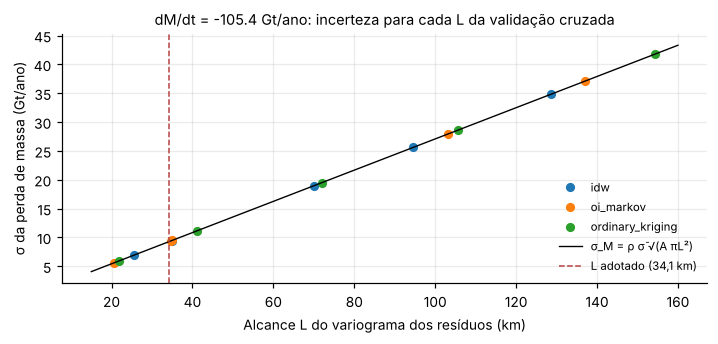

In [4]:
bm_djf = json.loads((DATA_DIR / "gelo_apoiado_balanco_massa_djf.json").read_text(encoding="utf-8"))
A_tot = bm_djf["area_total_km2"] * 1e6
rho = bm_djf["ice_density"]
dMdt = rho * bm_djf["dhdt_mean_m_yr"] * A_tot / 1e12
sle = -dMdt / 361.8

df_L = df_err_L.copy()
df_L["σ_M recalculado (Gt/ano)"] = rho * bm_djf["sigma_dhdt_bar_m_yr"] * np.sqrt(A_tot * np.pi * df_L["range_m"] ** 2) / 1e12

print(f"Área integrada: {bm_djf['area_total_km2']:,.0f} km² em {bm_djf['n_cells']:,} células de {bm_djf['cell_area_km2']:.0f} km²")
print(f"dh/dt médio (corrigido de firn): {bm_djf['dhdt_mean_m_yr']:+.4f} m/ano")
print(f"dM/dt = ρ × dh/dt × A = {dMdt:+.2f} Gt/ano (publicado: {bm_djf['dMdt_Gt_yr']:+.2f}) | nível do mar = {sle:+.3f} mm/ano")
print(f"σ independente = {bm_djf['sigma_dMdt_Gt_yr_independent']:.2f} Gt/ano | σ correlacionado (L = 34,1 km) = "
      f"{bm_djf['sigma_dMdt_Gt_yr_correlated']:.2f} Gt/ano → fator de inflação {bm_djf['inflation_factor']:.1f}×")

fig, ax = plt.subplots(figsize=(6.6, 3.2))
for meth, g in df_L.groupby("method"):
    ax.plot(g["range_km"], g["σ_M recalculado (Gt/ano)"], "o", ms=5, label=meth)
Lg = np.linspace(15, 160, 50)
ax.plot(Lg, rho * bm_djf["sigma_dhdt_bar_m_yr"] * np.sqrt(A_tot * np.pi * (Lg * 1e3) ** 2) / 1e12, "k-", lw=0.9,
        label="σ_M = ρ σ̄ √(A πL²)")
ax.axvline(34.1, color="#B64342", ls="--", lw=1, label="L adotado (34,1 km)")
ax.set_xlabel("Alcance L do variograma dos resíduos (km)"); ax.set_ylabel("σ da perda de massa (Gt/ano)")
ax.set_title(f"dM/dt = {dMdt:.1f} Gt/ano: incerteza para cada L da validação cruzada")
ax.legend(frameon=False, fontsize=7.5); plt.tight_layout()
df_L.pivot(index="method", columns="block_km", values="σ_M recalculado (Gt/ano)").round(1)

**Leitura do resultado.**
- A integração direta reproduz $-105{,}4\text{ Gt/ano}$ (0,29 mm/ano de nível do mar).
- A incerteza depende quase só de $L$: de ±5,6 a ±42 Gt/ano entre as 15 combinações de interpolador × bloco (recalculadas aqui com o $\bar\sigma$ do produto DJF). Mesmo no pior caso, a perda de massa continua inequivocamente diferente de zero (> 2,5σ).
- O fator de inflação de 12× entre o erro "independente" e o correlacionado mostra a magnitude da armadilha: reportar ±0,8 Gt/ano seria afirmar uma precisão que os dados não têm.

---
## 4. Correções de Firn e GIA e Validação Externa contra ATL15

**Fundamentação.** A altimetria mede a superfície. Parte do rebaixamento pode ser **compactação do firn** (perda de ar, não de gelo) e parte do sinal vertical é **movimento do embasamento** por ajuste isostático glacial (GIA). Ambos precisam ser removidos antes de converter em massa: $\dot h_{\text{gelo}} = \dot h - d\text{FAC}/dt - \dot B$.

,Valor
"Nós pareados com ATL15 (1 km, v005)",7233.0000
Correlação de Pearson r,0.9637
dh/dt mediano — este estudo (m/ano),-0.2816
dh/dt mediano — ATL15 (m/ano),-0.3271
Diferença mediana (m/ano),0.0443
Diferença RMS (m/ano),0.2309
Inclinação da regressão (este estudo vs. ATL15),0.8848
Razão JJA / ano inteiro no próprio ATL15,0.8623


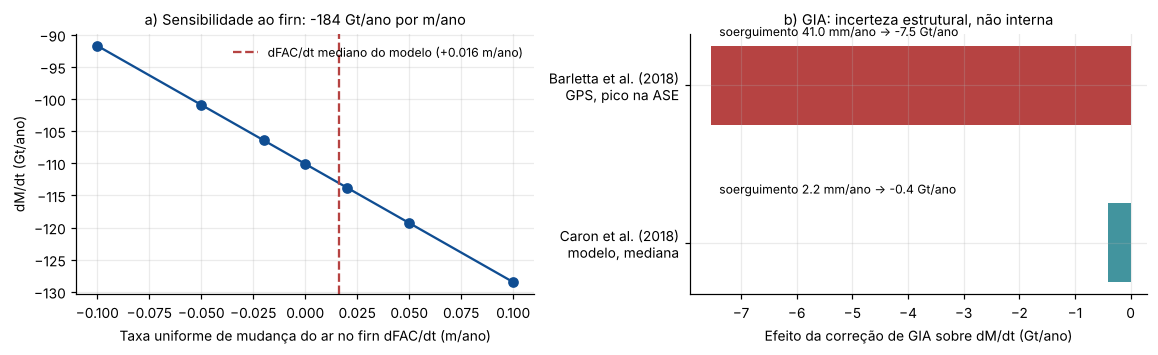

In [5]:
gia = json.loads((DATA_DIR / "gelo_apoiado_sensibilidade_gia.json").read_text(encoding="utf-8"))
atl15 = json.loads((DATA_DIR / "gelo_apoiado_validacao_atl15_djf.json").read_text(encoding="utf-8"))
mb_firn = json.loads((DATA_DIR / "jja_mass_balance_firn.json").read_text(encoding="utf-8"))

coef = np.polyfit(firn_sens["dfac_dt_m_yr"], firn_sens["dMdt_Gt_yr"], 1)
fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.3))
ax[0].plot(firn_sens["dfac_dt_m_yr"], firn_sens["dMdt_Gt_yr"], "o-", color="#0F4D92")
ax[0].axvline(mb_firn["firn_info"]["dfac_dt_median"], color="#B64342", ls="--",
              label=f"dFAC/dt mediano do modelo ({mb_firn['firn_info']['dfac_dt_median']:+.3f} m/ano)")
ax[0].set_xlabel("Taxa uniforme de mudança do ar no firn dFAC/dt (m/ano)"); ax[0].set_ylabel("dM/dt (Gt/ano)")
ax[0].set_title(f"a) Sensibilidade ao firn: {coef[0]:.0f} Gt/ano por m/ano"); ax[0].legend(frameon=False, fontsize=8)

vlm = {"Caron et al. (2018)\nmodelo, mediana": gia["sensibilidade_estrutural"]["vlm_caron_mediano_mm_ano"],
       "Barletta et al. (2018)\nGPS, pico na ASE": gia["sensibilidade_estrutural"]["vlm_barletta_gps_ase_mm_ano"]}
efeito = [gia["sensibilidade_estrutural"]["efeito_na_massa_caron_Gt_ano"], gia["sensibilidade_estrutural"]["efeito_na_massa_escala_barletta_Gt_ano"]]
ax[1].barh(list(vlm.keys()), efeito, color=["#42949E", "#B64342"], height=0.5)
for i, (k, v) in enumerate(vlm.items()):
    ax[1].text(min(efeito) * 0.98, i + 0.34, f"soerguimento {v:.1f} mm/ano → {efeito[i]:+.1f} Gt/ano", va="center", ha="left", fontsize=8)
ax[1].set_xlim(min(efeito) * 1.05, 0.3)
ax[1].set_xlabel("Efeito da correção de GIA sobre dM/dt (Gt/ano)"); ax[1].set_title("b) GIA: incerteza estrutural, não interna")
plt.tight_layout()

pd.DataFrame({
    "Valor": [atl15["n_nos_pareados"], atl15["correlacao_r"], atl15["nosso_dhdt_mediana"], atl15["atl15_dhdt_mediana"],
              atl15["diferenca_mediana"], atl15["diferenca_rms"], atl15["regressao_nosso_vs_atl15"]["slope"],
              atl15["vies_sazonal_JJA_sobre_anual"]],
}, index=["Nós pareados com ATL15 (1 km, v005)", "Correlação de Pearson r", "dh/dt mediano — este estudo (m/ano)",
          "dh/dt mediano — ATL15 (m/ano)", "Diferença mediana (m/ano)", "Diferença RMS (m/ano)",
          "Inclinação da regressão (este estudo vs. ATL15)", "Razão JJA / ano inteiro no próprio ATL15"]).round(4)

**Leitura do resultado.**
- **(a) Firn:** cada 1 cm/ano de erro uniforme em $d\text{FAC}/dt$ desloca ~1,8 Gt/ano. O modelo GSFC-FDM indica +1,6 cm/ano na mediana, uma correção pequena (−2 Gt/ano em JJA). A limitação declarada é que o modelo cobre só 2019–2022,5 (50% do período) e é extrapolado no restante.
- **(b) GIA:** o modelo de Caron et al. (2018) desloca a massa em apenas −0,4 Gt/ano, com σ de ensemble de décimos de mm/ano. O GPS de Barletta et al. (2018) mede soerguimento ~19× maior na ASE, o que equivaleria a −7,5 Gt/ano. **O σ do modelo não cobre a discrepância**: a incerteza do GIA aqui é estrutural (escolha de reologia), e a correção de Caron deve ser lida como piso.
- **ATL15:** o produto independente da NASA concorda nó a nó com $r = 0{,}96$. A inclinação de 0,88 e a diferença mediana de +0,044 m/ano (este estudo menos negativo) são explicadas em grande parte pela janela sazonal: no próprio ATL15, a taxa restrita ao inverno é 0,86 da taxa anual.

---

---
## 5. Séries Temporais de Massa por Temporada e Rebaixamento na Célula do Núcleo da Thwaites

Além da integração das grades krigadas corrigidas por firn ($-105{,}4 \pm 9{,}2\text{ Gt/ano}$ em DJF com $L = 34{,}1\text{ km}$, variando de $\pm 5{,}5$ a $\pm 41{,}8\text{ Gt/ano}$ para $L \in [20{,}5;\; 154{,}4]\text{ km}$, e efeito estrutural do GIA entre $-0{,}44\text{ Gt/ano}$ de Caron et al., 2018 e $-7{,}54\text{ Gt/ano}$ na escala do GPS de Barletta et al., 2018), construímos duas séries temporais independentes sem krigagem:
1. **Série regional de massa acumulada por temporada (`jja_serie_massa_temporada.json` e `djf_serie_massa_temporada.json`):** calculada diretamente sobre o painel balanceado de nós observados em todas as temporadas ($176.700\text{ km}^2$ em JJA e $169.025\text{ km}^2$ em DJF), resultando em taxas lineares de **$-91{,}6\text{ Gt/ano}$ (JJA)** e **$-89{,}6\text{ Gt/ano}$ (DJF)**;
2. **Série contínua de 13 temporadas na célula de $5\text{ km}$ do núcleo de afinamento da Thwaites ($75{,}34^\circ\text{S},\; 104{,}93^\circ\text{O}$, a $14{,}1\text{ km}$ da linha de aterramento; `celula_nucleo_thwaites_serie.csv`):** resolvida por regressão robusta de Huber com pesos balanceados por bloco orbital `(rgt, cycle)` sobre $14.457$ segmentos ATL06, revelando uma taxa de Theil–Sen de **$-4{,}35 \pm 0{,}10\text{ m/ano}$** (IC 95%: $-4{,}51$ a $-4{,}10\text{ m/ano}$; $-23{,}6\text{ m}$ acumulados, ou $-0{,}54\text{ Gt}$ apenas nessa célula de $25\text{ km}^2$), onde **todas as 12 transições consecutivas entre inverno e verão são negativas** e a variante com desconto de firn IMAU-FDM (2019–2023) fornece $-4{,}04 \pm 0{,}25\text{ m/ano}$.

,season,t_center,N_obs,N_blocks,dh_ice_m,sigma_dh_ice_m,dM_Gt,sigma_dM_Gt
window,,,,,,,,
JJA 2019,JJA,2019-07-27T13:04:32.155626+00:00,1405,3,0.000,0.000,0.000,0.000
DJF 2019/2020,DJF,2020-01-07T08:54:50.808091+00:00,1690,3,-1.139,0.561,-0.026,0.013
JJA 2020,JJA,2020-07-29T02:50:19.559816+00:00,531,1,-2.096,0.654,-0.048,0.015
DJF 2020/2021,DJF,2021-01-22T11:03:26.894441+00:00,910,3,-4.386,0.504,-0.101,0.012
JJA 2021,JJA,2021-08-20T21:21:48.054912+00:00,224,1,-6.886,0.549,-0.158,0.013
DJF 2021/2022,DJF,2022-01-23T13:14:52.830464+00:00,870,3,-9.557,0.523,-0.219,0.012
JJA 2022,JJA,2022-07-21T09:02:48.667033+00:00,1113,3,-11.077,0.506,-0.254,0.012
DJF 2022/2023,DJF,2023-01-01T04:53:04.563490+00:00,1756,3,-13.495,0.679,-0.309,0.016
JJA 2023,JJA,2023-07-22T11:13:14.110934+00:00,929,3,-15.999,0.497,-0.367,0.011


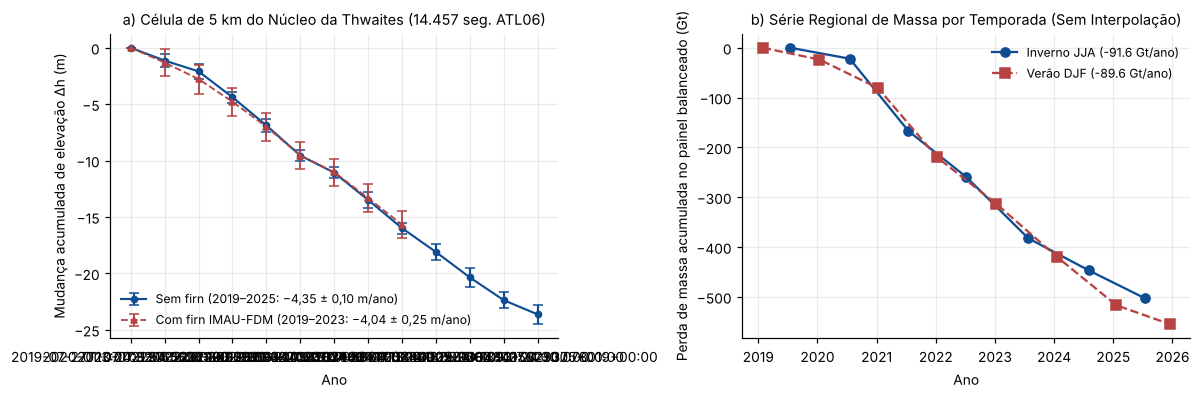

In [6]:
ser_jja = json.loads((DATA_DIR / "jja_serie_massa_temporada.json").read_text(encoding="utf-8"))
ser_djf = json.loads((DATA_DIR / "djf_serie_massa_temporada.json").read_text(encoding="utf-8"))
nuc_ser = pd.read_csv(DATA_DIR / "celula_nucleo_thwaites_serie.csv")
nuc_firn = pd.read_csv(DATA_DIR / "celula_nucleo_thwaites_com_firn_serie.csv")

df_sj = pd.DataFrame(ser_jja["serie"])
df_sd = pd.DataFrame(ser_djf["serie"])

fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.7))
ax[0].errorbar(nuc_ser["t_center"], nuc_ser["dh_ice_m"], yerr=nuc_ser["sigma_dh_ice_m"],
               fmt="o-", color="#0F4D92", lw=1.4, ms=4, capsize=3, label="Sem firn (2019–2025: −4,35 ± 0,10 m/ano)")
ax[0].errorbar(nuc_firn["t_center"], nuc_firn["dh_ice_m"], yerr=nuc_firn["sigma_dh_ice_m"],
               fmt="^--", color="#B64342", lw=1.2, ms=4, capsize=3, label="Com firn IMAU-FDM (2019–2023: −4,04 ± 0,25 m/ano)")
ax[0].set_xlabel("Ano")
ax[0].set_ylabel("Mudança acumulada de elevação Δh (m)")
ax[0].set_title("a) Célula de 5 km do Núcleo da Thwaites (14.457 seg. ATL06)")
ax[0].legend(frameon=False, fontsize=8)

ax[1].plot(df_sj["epoca_media"], df_sj["massa_acumulada_Gt"], "o-", color="#0F4D92", lw=1.5, label=f"Inverno JJA ({ser_jja['taxa_Gt_por_ano_ajuste_linear']:.1f} Gt/ano)")
ax[1].plot(df_sd["epoca_media"], df_sd["massa_acumulada_Gt"], "s--", color="#B64342", lw=1.5, label=f"Verão DJF ({ser_djf['taxa_Gt_por_ano_ajuste_linear']:.1f} Gt/ano)")
ax[1].set_xlabel("Ano")
ax[1].set_ylabel("Perda de massa acumulada no painel balanceado (Gt)")
ax[1].set_title("b) Série Regional de Massa por Temporada (Sem Interpolação)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

nuc_ser[["window", "season", "t_center", "N_obs", "N_blocks", "dh_ice_m", "sigma_dh_ice_m", "dM_Gt", "sigma_dM_Gt"]].set_index("window").round(3)

**Leitura da figura.**
- **(a)** A célula do núcleo da Thwaites rebaixou de forma monotônica: as 12 transições entre temporadas consecutivas são negativas, e o acumulado chega a −23,6 m em 6 anos. Descontar o firn (IMAU-FDM, disponível só até 2023) muda pouco a taxa (−4,04 vs. −4,35 m/ano): o sinal é dinâmico, não de compactação. Os poucos blocos orbitais por janela (`N_blocks` = 1–3) são a razão das barras de erro de ~0,5 m.
- **(b)** As duas séries regionais, construídas **sem krigagem** sobre os nós observados em todas as temporadas, dão −91,6 (JJA) e −89,6 Gt/ano (DJF) para uma área 12–16% menor que a do balanço krigado. Escaladas pela área, são consistentes com os −105 Gt/ano da Seção 3: a interpolação não está criando a perda de massa.

---
## 6. Síntese: Orçamento Final de Massa do Gelo Apoiado

In [7]:
jd = json.loads((DATA_DIR / "gelo_apoiado_jja_vs_djf_nos_comuns.json").read_text(encoding="utf-8"))
blk_jd = jd["por_bloco"]["20"]["JJA_menos_DJF"]
print(f"JJA − DJF nos {jd['n_nos_comuns']:,} nós comuns: {blk_jd['Gt_ano']:+.2f} ± {blk_jd['sigma_Gt_ano']:.2f} Gt/ano")

JJA − DJF nos 7,230 nós comuns: -5.42 ± 0.56 Gt/ano


In [8]:
orcamento = pd.DataFrame([
    {"Componente": "Perda de massa (DJF, krigagem, corrigida de firn)", "Valor (Gt/ano)": bm_djf["dMdt_Gt_yr"],
     "σ (Gt/ano)": bm_djf["sigma_dMdt_Gt_yr_correlated"], "Comentário": "L = 34,1 km (bloco de 50 km)"},
    {"Componente": "Faixa de σ para L ∈ [20,5; 154,4] km", "Valor (Gt/ano)": np.nan,
     "σ (Gt/ano)": np.nan, "Comentário": f"±{df_L['σ_M recalculado (Gt/ano)'].quantile(0):.1f} a ±{df_L['σ_M recalculado (Gt/ano)'].max():.1f} Gt/ano"},
    {"Componente": "Efeito do firn (JJA, GSFC-FDM)", "Valor (Gt/ano)": mb_firn["delta_Gt_yr"], "σ (Gt/ano)": np.nan,
     "Comentário": "modelo cobre 50% do período"},
    {"Componente": "Efeito do GIA (Caron 2018) / escala GPS (Barletta 2018)",
     "Valor (Gt/ano)": gia["efeito_da_correcao_Gt_ano"], "σ (Gt/ano)": np.nan,
     "Comentário": f"até {gia['sensibilidade_estrutural']['efeito_na_massa_escala_barletta_Gt_ano']:.1f} Gt/ano na escala do GPS"},
    {"Componente": "Diferença sazonal JJA − DJF (nós comuns)", "Valor (Gt/ano)": blk_jd["Gt_ano"], "σ (Gt/ano)": blk_jd["sigma_Gt_ano"],
     "Comentário": "sistemático, ~6% do sinal"},
    {"Componente": "Contribuição ao nível do mar", "Valor (Gt/ano)": np.nan, "σ (Gt/ano)": np.nan,
     "Comentário": f"{bm_djf['sle_mm_yr']:.2f} ± {bm_djf['sigma_sle_mm_yr_correlated']:.2f} mm/ano"},
]).set_index("Componente")
orcamento.round(2)

,Valor (Gt/ano),σ (Gt/ano),Comentário
Componente,,,
"Perda de massa (DJF, krigagem, corrigida de firn)",-105.44,9.23,"L = 34,1 km (bloco de 50 km)"
"Faixa de σ para L ∈ [20,5; 154,4] km",NaN,NaN,±5.6 a ±41.8 Gt/ano
"Efeito do firn (JJA, GSFC-FDM)",-1.99,NaN,modelo cobre 50% do período
Efeito do GIA (Caron 2018) / escala GPS (Barletta 2018),-0.45,NaN,até -7.5 Gt/ano na escala do GPS
Diferença sazonal JJA − DJF (nós comuns),-5.42,0.56,"sistemático, ~6% do sinal"
Contribuição ao nível do mar,NaN,NaN,0.29 ± 0.03 mm/ano


**Conclusões do caderno.**
1. A bacia do Mar de Amundsen perdeu **$-105 \pm 9\text{ Gt/ano}$** de gelo apoiado em 2019–2025 (0,29 ± 0,03 mm/ano de nível do mar). O sinal supera a incerteza em todas as escolhas de $L$ testadas.
2. A barra de erro é dominada pela **correlação espacial geofísica** do resíduo, não pelo instrumento. O erro de apontamento contribui com ~13% no nível nodal.
3. As correções de firn e GIA são pequenas frente à incerteza, mas a do GIA tem **incerteza estrutural aberta** de até ~7 Gt/ano, que não está na barra de erro formal.
4. Séries sem interpolação, a célula do núcleo da Thwaites e a comparação com ATL15 confirmam a magnitude e a forma do sinal.

**Scripts do pipeline:** `pipelines/gelo_apoiado/run_uncertainty.py`, `run_sigma_corr.py`, `run_mass_balance.py`, `run_firn.py`, `run_gia.py`, `run_atl15_validation.py`, `run_timeseries.py`, `pipelines/figures/run_grounded_seasonal_mass_report.py`.

**Próximo caderno:** o Caderno 05 atravessa a linha de aterramento e estuda como as plataformas flutuantes respondem à maré.